In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings('ignore')

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [2]:
df = pd.read_csv('laptop_scenarios_story_text.csv')
df.head()

,user_profile,budget_class,price_tier,story_text,upgrade_first,gain_class
0,student,low,high,My main problem with this Apple Ultrabook is s...,Storage,Low
1,student,medium,high,"For anyone curious, this Apple Ultrabook has b...",Storage,Low
2,student,high,high,I would describe my Apple Ultrabook like this:...,Storage,Low
3,office,low,high,My take on this Apple Ultrabook is that it loo...,Storage,Low
4,office,medium,high,Current machine note: I am using an Apple Ultr...,Storage,Low


# **Input Story**

In [3]:
input_story = df['story_text'].iloc[0]
print(f"  Row Index    : {0}")
print(f"  User Profile : {df['user_profile'].iloc[0]}")
print(f"  Budget Class : {df['budget_class'].iloc[0]}")
print(f"  Price Tier   : {df['price_tier'].iloc[0]}")
print(f"  Upgrade First: {df['upgrade_first'].iloc[0]}")
print(f"  Gain Class   : {df['gain_class'].iloc[0]}")
print("Story Text:", input_story)

  Row Index    : 0
  User Profile : student
  Budget Class : low
  Price Tier   : high
  Upgrade First: Storage
  Gain Class   : Low
Story Text: My main problem with this Apple Ultrabook is simple: as a student, I keep finding the same limits over and over. The core specs are Intel Core i5 at 2.3GHz, 8GB of RAM, 128GB SSD, and Intel Integrated graphics. It has to keep up with study sessions, online lectures, writing, and too many tabs open at once. I keep running into the limits of the 128GB total storage, especially with 128GB SSD. I do like that it is an Apple Ultrabook running macOS, and the machine feels fairly light in a bag. For student use, I mainly want the machine to feel uncomplicated and dependable. Because the budget is low, I have to be selective and focus on the biggest pain point first.


In [4]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

df_left = df.drop(index=0).reset_index(drop=True)
cleaned_input = preprocess_text(input_story)
df_left['cleaned'] = df_left['story_text'].apply(preprocess_text)

print("Preprocessing done.")
print(f"Candidates available: {len(df_left)}")


Preprocessing done.
Candidates available: 19544


In [5]:
all_texts = [cleaned_input] + df_left['cleaned'].tolist()

vectorizer = TfidfVectorizer(stop_words='english', max_features=500, min_df=2)
tfidf_matrix = vectorizer.fit_transform(all_texts)

similarity_scores = cosine_similarity(tfidf_matrix[0], tfidf_matrix[1:]).flatten()

print(f"Similarity scores computed for {len(similarity_scores)} stories.")
print(f"Max: {similarity_scores.max():.4f} | Mean: {similarity_scores.mean():.4f}")

Similarity scores computed for 19544 stories.
Max: 0.7185 | Mean: 0.1589


In [6]:
top5 = np.argsort(similarity_scores)[::-1][:5]

print("Top 5 Most Similar Cases:")
for rank, idx in enumerate(top5, 1):
    print(f"\nRank {rank} | Similarity: {similarity_scores[idx]:.4f}")
    print(f"  Upgrade: {df_left['upgrade_first'].iloc[idx]} | Gain: {df_left['gain_class'].iloc[idx]}")
    print(f"  Story  : {df_left['story_text'].iloc[idx][:120]}...")

Top 5 Most Similar Cases:

Rank 1 | Similarity: 0.7185
  Upgrade: No Upgrade Needed | Gain: Low
  Story  : I sat down with my Apple Ultrabook again today and noticed, once more, how it fits some parts of my student routine bett...

Rank 2 | Similarity: 0.6966
  Upgrade: No Upgrade Needed | Gain: Low
  Story  : Current machine note: I am using an Apple Ultrabook for student work, and the practical experience is uneven. The core s...

Rank 3 | Similarity: 0.6832
  Upgrade: Storage | Gain: Medium
  Story  : My main problem with this Apple Ultrabook is simple: as a student, I keep finding the same limits over and over. The set...

Rank 4 | Similarity: 0.6820
  Upgrade: No Upgrade Needed | Gain: Low
  Story  : Observed in daily use, this Apple Ultrabook behaves like a device that was built with some of my student needs in mind, ...

Rank 5 | Similarity: 0.6414
  Upgrade: No Upgrade Needed | Gain: Low
  Story  : For anyone curious, this Apple Ultrabook has been my machine for student use, an

In [15]:
THRESHOLD = 0.55
MAX_NODES = 15

above = np.where(similarity_scores >= THRESHOLD)[0]
selected = np.argsort(similarity_scores)[::-1][:MAX_NODES]

print(f"Stories above threshold ({THRESHOLD}): {len(above)}")
print(f"Stories included in graph: {len(selected)}")

G = nx.Graph()

G.add_node('INPUT', node_type='input')

for idx in selected:
    node_id = f'Case_{idx}'
    G.add_node(node_id, node_type='case')
    G.add_edge('INPUT', node_id, weight=round(float(similarity_scores[idx]), 4))

case_vectors = tfidf_matrix[selected + 1]
case_sim = cosine_similarity(case_vectors)

for i in range(len(selected)):
    for j in range(i + 1, len(selected)):
        if case_sim[i, j] >= THRESHOLD:
            G.add_edge(f'Case_{selected[i]}', f'Case_{selected[j]}',
                       weight=round(float(case_sim[i, j]), 4))

print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Stories above threshold (0.55): 33
Stories included in graph: 15
Graph: 16 nodes, 54 edges


# **Graph Visual**

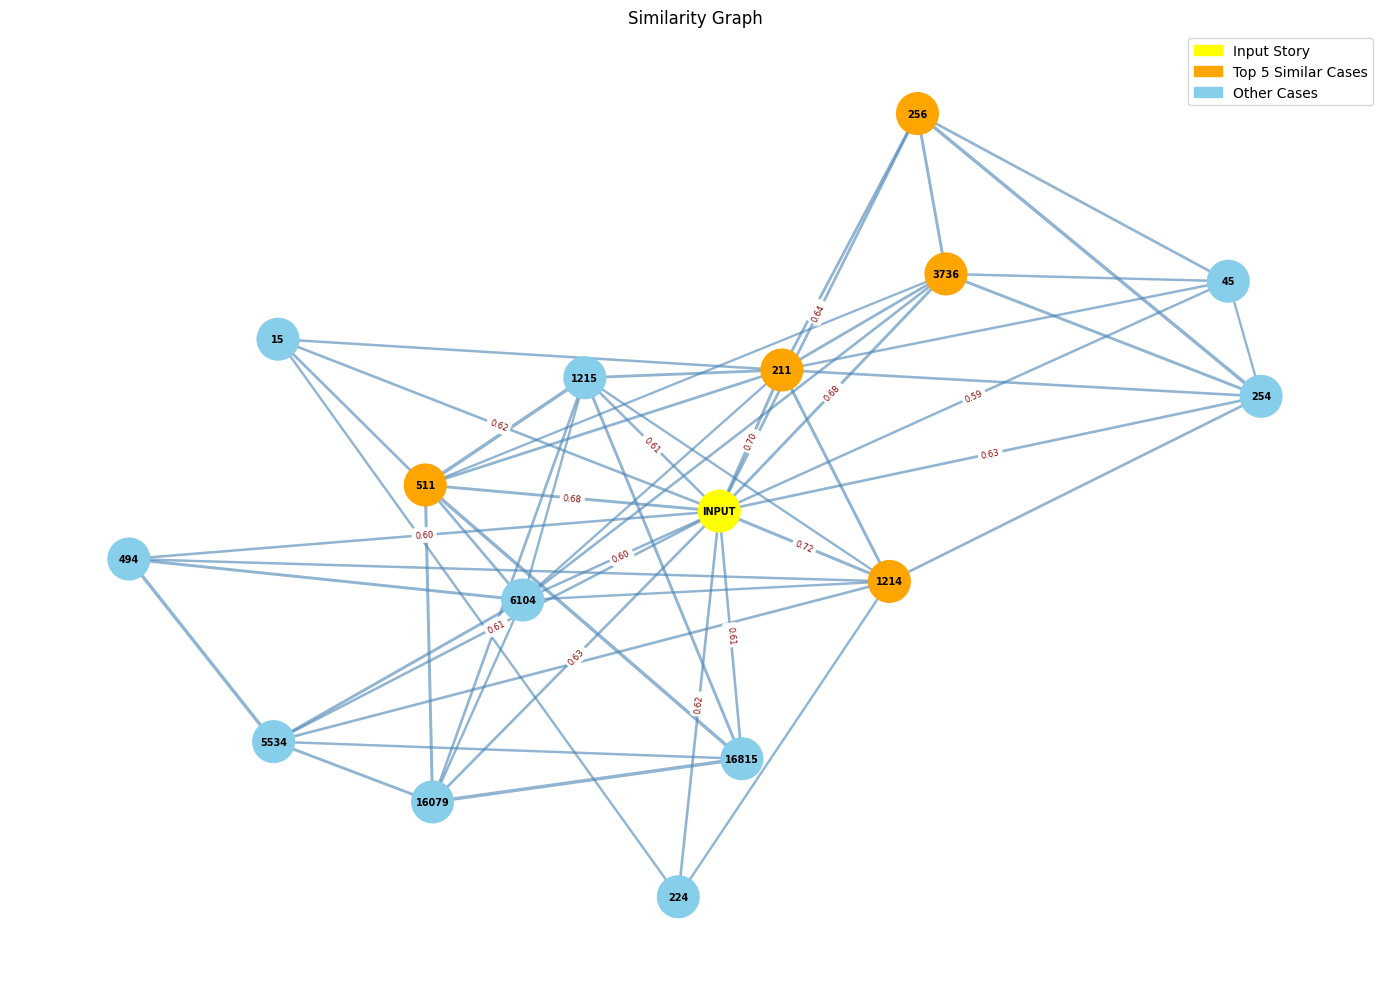

In [16]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, k=1.2)

top5 = [f'Case_{idx}' for idx in np.argsort(similarity_scores)[::-1][:5]]

colors = ['yellow' if n == 'INPUT' else 'orange' if n in top5 else 'skyblue' for n in G.nodes()]

nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=900)
nx.draw_networkx_labels(G, pos, labels={n: n.replace('Case_', '') for n in G.nodes()}, font_size=7, font_weight='bold')

weights = [d['weight'] for _, _, d in G.edges(data=True)]
nx.draw_networkx_edges(G, pos, width=[2.5 * (w / max(weights)) for w in weights], edge_color='steelblue', alpha=0.6)

nx.draw_networkx_edge_labels(G, pos, edge_labels={(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True) if 'INPUT' in (u, v)}, font_size=6, font_color='darkred')

plt.legend(handles=[
    mpatches.Patch(color='yellow',  label='Input Story'),
    mpatches.Patch(color='orange',  label='Top 5 Similar Cases'),
    mpatches.Patch(color='skyblue', label='Other Cases')
])

plt.title("Similarity Graph")
plt.axis('off')
plt.tight_layout()
plt.show()

# **Metrics Table**

In [17]:
pagerank    = nx.pagerank(G, weight='weight')
degree      = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(G, weight='weight', normalized=True)
closeness   = nx.closeness_centrality(G)

rows = []
for n in G.nodes():
    rows.append([n, round(pagerank[n],4), round(degree[n],4), round(betweenness[n],4), round(closeness[n],4)])

metrics_df = pd.DataFrame(rows, columns=['Node','PageRank','Degree','Betweenness','Closeness'])
metrics_df = metrics_df.sort_values('PageRank', ascending=False).reset_index(drop=True)

print(metrics_df.to_string(index=False))

      Node  PageRank  Degree  Betweenness  Closeness
     INPUT    0.1291  1.0000       0.3143     1.0000
  Case_211    0.0880  0.6667       0.0667     0.7500
  Case_511    0.0764  0.5333       0.0095     0.6818
 Case_6104    0.0759  0.6000       0.0762     0.7143
 Case_1214    0.0711  0.5333       0.0857     0.6818
 Case_3736    0.0635  0.4667       0.0286     0.6522
 Case_1215    0.0633  0.4667       0.0000     0.6522
 Case_5534    0.0580  0.4000       0.0095     0.6250
Case_16079    0.0577  0.4000       0.0000     0.6250
  Case_254    0.0572  0.4000       0.0095     0.6250
Case_16815    0.0514  0.3333       0.0000     0.6000
  Case_256    0.0511  0.3333       0.0000     0.6000
   Case_45    0.0448  0.3333       0.0000     0.6000
  Case_494    0.0417  0.2667       0.0000     0.5769
   Case_15    0.0397  0.2667       0.0190     0.5769
  Case_224    0.0313  0.2000       0.0095     0.5556


In [21]:
case_nodes = [n for n in G.nodes() if n != 'INPUT']

most_representative = max(case_nodes, key=lambda n: pagerank[n])
most_connected = max(case_nodes, key=lambda n: degree[n])
bridge_case = max(case_nodes, key=lambda n: betweenness[n])
closest_case = max(case_nodes, key=lambda n: closeness[n])
unusual_case = min(case_nodes, key=lambda n: pagerank[n])

print("Most Representative Case:", most_representative)
print("Most Connected Case:", most_connected)
print("Bridge Case:", bridge_case)
print("Closest Case:", closest_case)
print("Unusual Case:", unusual_case)

Most Representative Case: Case_211
Most Connected Case: Case_211
Bridge Case: Case_1214
Closest Case: Case_211
Unusual Case: Case_224


# **Explanation**

The similarity graph shows the network constructed from the input story selected from the dataset, with 15 other similar cases.
Each node is for a story input and each edge is the similarity relationship between each 2 nodes.

The center node in Yellow is the input which is connected to all the other nodes. All nodes in the graph exceeded the Threshold=0.55, which is the similarity score threshhold. So the graph shows the similarity relationships between the cases.

The similarity shows that cases are relatively dense. so they have common words like theme or issue or experience. The more tight the cases are the more they are similar in the laptop problem. The wieghts are the strength of these realtionships, the higher means the stronger textual similarity between them.

**Most representative case**

the case 211 is the most representative case, bec it had the highest pagerank 0.0880. PageRank is the measure that finds the overall perfoemance of a node based on the quality of its connections and the number

**Most connected case**

the most connected case is Case 211 also, bec it had the highest degree centrality of 0.67. the degree centrality is the measure that finds the proportion of direct connections the node has with others.

**bridge case**

the bridge case is case 1214 which has the highest betweenness centrality 0.0857. betweenness centrality measures how ofte thehis node lies on the shortest path. so this node is important for connecting different groups of similar stories which increases connectivity.

**closest case**

is case 211 with 0.75 closeness centrality, which is the highest. it is the quickest to reach to other nodes in the network.

**unusual case**

which is case 224, with 0.0313 which is the lowest pagerank and lowest degree centrality of 0.2. it has less similarity realtionships. this means that its content is different from common themes in the majority class, which is the least representative and most isolated from other nodes in the graph

# **Use of Python and NetworkX**

The use of Python And network X help find and implement graph data mining. Network X is a library that gives straightforward functions that's helped in building graphs for data sets adding their weighted edges and drawing visualisations to understand the graph more, it also provides metrics like pagerank, degree centrality, betweenness centrality and closeness centrality to be able to evaluate and understand the correlation between nodes properly.

The use of pandas and matplotlib help in visualising the graphs and out putting clean tables to read the edge weights(similarity relationships) and node labels (stories). Network X helps in handling the graph structure and the calculations at outputs without no needing any extra tool, but a limitation could be the randomness of producing different visual arrangements each time only if the random is not fixed. Moreover, network X could be slow for large data sets so it's not ideal for scaling the dataset.
